![logo](https://climate.copernicus.eu/sites/default/files/2025-03/logoline_c3s.png)

# Analysis of projected versus historical climatology with CORDEX data

**Last updated:** 2026-10-12

**This notebook can be run on free online platforms, such as Binder, Kaggle and Colab, or they can be accessed from GitHub. The links to run this notebook in these environments are provided here, but please note they are not supported by ECMWF.**

[![binder](https://mybinder.org/badge.svg)](https://mybinder.org/v2/gh/ecmwf-training/c3s-training-submodule-projections/main?labpath=projections-cordex.ipynb)
[![kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ecmwf-training/c3s-training-submodule-projections/blob/main/projections-cordex.ipynb)
[![colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecmwf-training/c3s-training-submodule-projections/blob/main/projections-cordex.ipynb)
[![github](https://img.shields.io/badge/Open%20in-GitHub-black?logo=github)](https://github.com/ecmwf-training/c3s-training-submodule-projections/blob/main/projections-cordex.ipynb)

## Learning objectives 🎯

This notebook is a practical introduction to [CORDEX regional climate model data on single levels](https://cds.climate.copernicus.eu/datasets/projections-cordex-domains-single-levels?tab=overview). This workflow will demonstrate how to compute the difference in the air temperature climatology for 2071-2100 (according to a projected scenario) relative to the reference period 1971-2000 in Africa, with a spatial resolution of 0.44 x 0.44 degrees.

We will use the historical experiment to compute the past climatology and repeat the steps to compute the projected climatology according to the scenario RCP4.5. Finally, we will take the difference between the two in order to assess the extent of change. This is called the "delta method" which takes the climate change signal as the difference between the future and past considering that the model biases are the same and can therefore be removed with the subtraction.

## Prepare your environment

### Install earthkit and cdsapi

We will request data from the Climate Data Store (CDS) with the help of [earthkit](https://earthkit-data.readthedocs.io/en/latest/).

The code below will ensure that the `earthkit` and `cdsapi` packages are installed.  earthkit-data's `cds` source uses the `cdsapi` package under the hood to talk to the CDS, so `cdsapi` needs to be installed too, even though we never import or call it directly.

In [ ]:
%pip install -q earthkit cdsapi

### (Install and) Import libraries

In [1]:
# Library to get the name of a month from its number
import calendar

# earthkit for retrieving, processing and visualising CDS data
from earthkit import data as ekd
from earthkit import transforms as ekt
from earthkit import plots as ekp
from earthkit.utils.units.convert import convert_units

# Disable warnings for data download via API
import urllib3

urllib3.disable_warnings()

## Explore data

CORDEX data are available for 14 regional domains and variable spatial resolutions, from 0.11 x 0.11 degrees up to 0.44 x 0.44 degrees. This particular example uses data from the Canadian Regional Climate Model `CCCma_CanRCM4`, with lateral boundary conditions from the Global Climate Model (GCM) `CanESM2`, also Canadian. This coupled model is referred to as `CanRCM4 - CanESM2`. See [here](https://confluence.ecmwf.int/display/CKB/CORDEX%3A+Regional+climate+projections#CORDEX:Regionalclimateprojections-DrivingGlobalClimateModelsandRegionalClimateModels) a full list of models included in the CDS-CORDEX subset.

<br>

In general, CORDEX experiments can be divided into three main categories:

* **Evaluation**: model simulations for the past with imposed "perfect" lateral boundary conditions following ERA-Interim reanalysis (1979-2015).

* **Historical**: Historical experiments cover the period where modern climate observations exist. These experiements show how the RCMs perform for the past climate when forced by the Global Circulation Model (GCM) and can be used as a reference period for comparison with scenario runs for the future.

* **Scenario experiments RCP2.6, RCP4.5, RCP8.5**: ensemble of CORDEX climate projection experiments driven by boundary conditions from GCMs using RCP (Representative Concentration Pathways) forcing scenarios. The scenarios used here are RCP 2.6, 4.5 and 8.5, which provide different pathways of the future climate forcing.

Learn [here](https://confluence.ecmwf.int/display/CKB/CORDEX%3A+Regional+climate+projections#CORDEX:Regionalclimateprojections-Experiments) more about CORDEX experiments in the Copernicus Climate Data Store (CDS).

:::{note}

The workflow uses a specific model, scenario and geographical area, but you can use any model, scenario or domain, and indeed any period or variable. To have a more accurate idea of projected climate change, it is typical to calculate an ensemble of multiple models. Only for the sake of simplicity do we focus on one model.

:::

### Search for the data

We will use data from two datasets:

* **Historical experiment**: Daily aggregated historical 2m air temperature (from the CanRCM4 - CanESM2 model) from 1971 to 2000 for Africa.
* **RCP4.5 experiment**: Daily aggregated RCP4.5 projections of 2m air temperature (from the CanRCM4 - CanESM2 model) from 2071 to 2100 for Africa

Having selected the [CORDEX regional climate model data on single levels](https://cds.climate.copernicus.eu/datasets/projections-cordex-domains-single-levels?tab=overview) dataset in the CDS, we now need to specify what product type, variables, temporal and geographic coverage we are interested in. These can all be selected in the **"Download data"** tab. In this tab a form appears in which we will select the following parameters to download:

:::{dropdown} Parameters of data to download

- Data: `CORDEX regional climate model data on single levels - Experiment: Historical`
- Temporal coverage: `1 Jan 1971 to 31 Dec 2000`
- Spatial coverage: `Domain: Africa`
- Format: `NetCDF in zip archives`

- Data: `CORDEX regional climate model data on single levels - Experiment: RCP4.5`
- Temporal coverage: `1 Jan 2071 to 31 Dec 2100`
- Spatial coverage: `Domain: Africa`
- Format: `NetCDF in zip archives`

:::

At the end of the download form, select **"Show API request"**. This will reveal a block of code, which you can simply copy and paste into a cell of your Jupyter Notebook (see cell below). Having copied the API request into the cell below, running this will retrieve and download the data you requested.

:::{warning}

Please remember to accept the terms and conditions of the dataset, at the bottom of the CDS download form!

:::

### Download the data

With the API request copied into the cells below, running these cells will retrieve and download the data you requested.

If you have not set up your .cdsapirc file, you will be prompted for your CDS credentials when executing the download cell. See [how to api](https://cds.climate.copernicus.eu/how-to-api) for details on how to set up your .cdsapirc file.

In [2]:
source = "cds"
dataset = "projections-cordex-domains-single-levels"
request = {
    "download_format": "zip",
    "data_format": "netcdf",
    "domain": "africa",
    "experiment": "historical",
    "horizontal_resolution": "0_44_degree_x_0_44_degree",
    "temporal_resolution": "daily_mean",
    "variable": "2m_air_temperature",
    "gcm_model": "cccma_canesm2",
    "rcm_model": "cccma_canrcm4",
    "ensemble_member": "r1i1p1",
    "start_year": ["1971", "1976", "1981", "1986", "1991", "1996"],
    "end_year": ["1975", "1980", "1985", "1990", "1995", "2000"],
}

data_historical = ekd.from_source(source, dataset, request)

2026-10-12 16:33:38,815 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 16:33:40,788 INFO [2026-07-09T00:00:00] Temporal and spatial sub-selection has been added to this catalogue entry. Please refer to the [updated documentation](https://confluence.ecmwf.int/spaces/CKB/pages/181113935/CORDEX+Regional+climate+projections#CORDEX:Spatialandtemporalsubsetting) for more details. **API users**, please note that previous requests are no longer compatible with the dataset. Further details are provided

e6decf423d7964e30a3e044a5e3c7a5c.zip:   0%|          | 0.00/1.66G [00:00<?, ?B/s]

  0%|          | 0/14 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmp26bm8_yg/cds-a1b2e250a154b33ecb7eb939a0708497652d5d44a00411a320f3b987f528a366.d/provenance.png magic=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x0b\xb1\x00\x00\x03\x10\x08\x06\x00\x00\x00K\xa0\x03W\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xddy' content_type=None


In [3]:
request = {
    "download_format": "zip",
    "data_format": "netcdf",
    "domain": "africa",
    "experiment": "rcp_4_5",
    "horizontal_resolution": "0_44_degree_x_0_44_degree",
    "temporal_resolution": "daily_mean",
    "variable": "2m_air_temperature",
    "gcm_model": "cccma_canesm2",
    "rcm_model": "cccma_canrcm4",
    "ensemble_member": "r1i1p1",
    "start_year": ["2071", "2076", "2081", "2086", "2091", "2096"],
    "end_year": ["2075", "2080", "2085", "2090", "2095", "2100"],
}

data_rcp45 = ekd.from_source(source, dataset, request)

2026-10-12 16:50:55,033 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 16:50:58,009 INFO [2026-07-09T00:00:00] Temporal and spatial sub-selection has been added to this catalogue entry. Please refer to the [updated documentation](https://confluence.ecmwf.int/spaces/CKB/pages/181113935/CORDEX+Regional+climate+projections#CORDEX:Spatialandtemporalsubsetting) for more details. **API users**, please note that previous requests are no longer compatible with the dataset. Further details are provided

b8e454da12493155d06c4d19b20a7a6d.zip:   0%|          | 0.00/2.81G [00:00<?, ?B/s]

  0%|          | 0/21 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmp26bm8_yg/cds-e07e4806292fed3bf34d31f660187e5b6a68fe61c38e7166f66227582e5a6efd.d/provenance.png magic=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x0bt\x00\x00\x03\x10\x08\x02\x00\x00\x00ZTQ\xe5\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xddy' content_type=None


:::{note}

From the Copernicus Climate Data Store, CORDEX data are available in `NetCDF` format in compressed archives. CORDEX files are generally organised in five year periods, so each of the two archives we downloaded contains six `NetCDF` files. earthkit takes care of extracting the files from the archives for us, so there is no need to unzip them ourselves. earthkit also caches the downloaded data: if you run the download cells again with the same requests, the data will be taken from the cache instead of being downloaded again.

:::

## Compute CORDEX historical climatology for reference period 1971-2000

The first step is to load the data of the `historical` experiment. The earthkit data object can be converted straight to an [xarray.Dataset](https://xarray.pydata.org/en/stable/generated/xarray.Dataset.html) with the method `to_xarray()`. As the archive contains several `NetCDF` files, earthkit reads and concatenates them all at once (using the Xarray function `open_mfdataset`).

The result is a `xarray.Dataset` object with four dimensions: `bnds`, `rlat`, `rlon`, `time`, of which the dimension `bnds` is not callable.

In [4]:
ds_1971_2000_historical = data_historical.to_xarray()
ds_1971_2000_historical

/opt/miniconda3/envs/esmf_env/lib/python3.11/site-packages/earthkit/data/readers/netcdf/reader.py:61: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.open_mfdataset(


<xarray.Dataset> Size: 3GB
Dimensions:       (time: 20440, rlat: 201, rlon: 194, bnds: 2)
Coordinates:
  * time          (time) object 164kB 1950-01-01 12:00:00 ... 2005-12-31 12:0...
  * rlat          (rlat) float64 2kB -45.76 -45.32 -44.88 ... 41.36 41.8 42.24
  * rlon          (rlon) float64 2kB -24.64 -24.2 -23.76 ... 59.4 59.84 60.28
    lon           (rlat, rlon) float64 312kB dask.array<chunksize=(201, 194), meta=np.ndarray>
    lat           (rlat, rlon) float64 312kB dask.array<chunksize=(201, 194), meta=np.ndarray>
    height        float64 8B 2.0
Dimensions without coordinates: bnds
Data variables:
    rotated_pole  (time) |S1 20kB b'' b'' b'' b'' b'' ... b'' b'' b'' b'' b''
    tas           (time, rlat, rlon) float32 3GB dask.array<chunksize=(1, 201, 194), meta=np.ndarray>
    time_bnds     (time, bnds) object 327kB dask.array<chunksize=(1, 2), meta=np.ndarray>
Attributes: (12/26)
    title:                          CanRCM4 model output prepared for CORDEX ...
    institution:                    CCCma (Canadian Centre for Climate Modell...
    institute_id:                   CCCma
    contact:                        cccma_info@ec.gc.ca
    Conventions:                    CF-1.4
    experiment:                     Historical run driven by CCCma-CanESM2
    ...                             ...
    history:                        created: 2012-06-29 23:52:01 by rcm2nc
    data_licence:                   1) GRANT OF LICENCE - The Government of C...
    creation_date:                  2012-06-29-T23:47:03Z
    c3s_comment:                    This data has been published at ESGF with...
    tracking_id:                    hdl:21.14103/2cfda0e3-e8d8-49c3-9a0a-04c0...
    c3s_disclaimer:                 This data has been curated and prepared i...

The next step is to load the data variable `tas` from the Dataset above. We can load data variables by adding the name of the variable (`tas`) in square brackets. The resulting object is a `xarray.DataArray`, which offers additional metadata information about the data, e.g. the `unit` or `long_name` of the variable.

In [5]:
tas_1971_2000_historical = ds_1971_2000_historical["tas"]
tas_1971_2000_historical

<xarray.DataArray 'tas' (time: 20440, rlat: 201, rlon: 194)> Size: 3GB
dask.array<concatenate, shape=(20440, 201, 194), dtype=float32, chunksize=(1, 201, 194), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 164kB 1950-01-01 12:00:00 ... 2005-12-31 12:00:00
  * rlat     (rlat) float64 2kB -45.76 -45.32 -44.88 -44.44 ... 41.36 41.8 42.24
  * rlon     (rlon) float64 2kB -24.64 -24.2 -23.76 -23.32 ... 59.4 59.84 60.28
    lon      (rlat, rlon) float64 312kB dask.array<chunksize=(201, 194), meta=np.ndarray>
    lat      (rlat, rlon) float64 312kB dask.array<chunksize=(201, 194), meta=np.ndarray>
    height   float64 8B 2.0
Attributes:
    long_name:      Near-Surface Air Temperature
    standard_name:  air_temperature
    units:          K
    grid_mapping:   rotated_pole
    cell_methods:   time: mean

We will now compute the monthly climatology for the reference period. The monthly climatology represents for each month, and each grid point, the average value over the reference period of 30 years, from 1971 to 2000. We can compute the climatology for each grid point with earthkit's function `climatology.monthly_mean`, specifying the reference period with `climatology_range`.

The result is a three-dimensional DataArray with the dimensions `month`, `rlat` and `rlon`. The operation has replaced the `time` dimension by `month`, which has the average near-surface air temperature for each month.

In [6]:
tas_1971_2000_climatology = ekt.climatology.monthly_mean(
    tas_1971_2000_historical, climatology_range=("1971", "2000")
)

In a last step, we want to convert the near-surface air temperature values in Kelvin to degrees Celsius. We can do this with earthkit's function `convert_units`.

In [7]:
tas_1971_2000_climatology_degC = convert_units(tas_1971_2000_climatology, "degC", "K")

## Compute CORDEX future climatology for target period 2071-2100 based on scenario RCP4.5

Let us now repeat the steps executed for the historical experiment data with the `scenario RCP4.5` data. With the projection data for the target period 2071 to 2100, we can compute the projected climatology according to this particular scenario, which can be compared with the historical climatology from the reference period.

Again, we begin by converting the earthkit data object to an Xarray Dataset. The scenario data is also organised into separate files for each 5-year period. These will be concatenated along the `time` dimension.

In [8]:
ds_2071_2100_projection = data_rcp45.to_xarray()

/opt/miniconda3/envs/esmf_env/lib/python3.11/site-packages/earthkit/data/readers/netcdf/reader.py:61: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.open_mfdataset(


Again we load the data variable `tas` from the Dataset above into an `xarray.DataArray` object to facilitate further processing:

In [9]:
tas_2071_2100_projection = ds_2071_2100_projection["tas"]

# uncomment the line below before running this cell to view the data characteristics
# tas_2071_2100_projection

Now we will compute the monthly climatology for the target period 2071 to 2100, in the same way as we did for the historical period:

In [10]:
tas_2071_2100_climatology = ekt.climatology.monthly_mean(
    tas_2071_2100_projection, climatology_range=("2071", "2100")
)

And finally we convert from degrees Kelvin to Celsius:

In [11]:
tas_2071_2100_climatology_degC = convert_units(tas_2071_2100_climatology, "degC", "K")

## Compute and visualize the climate change signal between the target (2071-2100) and reference (1971-2000) period

Now, we can compute the difference between the two climatologies. Since both DataArrays have the same structure, we can simply subtract the historical climatology from the projected climatology. The resulting data array has the projected averaged temperature difference for each month.

We also give the result a descriptive name and its units, which earthkit uses to label the plots.

In [12]:
tas_difference_climatology = (
    tas_2071_2100_climatology_degC - tas_1971_2000_climatology_degC
)
tas_difference_climatology.attrs = {
    "long_name": "Near-surface air temperature difference",
    "units": "°C",
}

CORDEX data are provided on a rotated grid. The coordinates `rlat` and `rlon` give the position of each grid point on the rotated grid, while the two-dimensional coordinates `lat` and `lon` give its geographical latitude and longitude. To plot the data on a map, we drop the rotated coordinates, so that earthkit places each grid point using its geographical latitude and longitude:

In [13]:
tas_difference_climatology = tas_difference_climatology.drop_vars(["rlat", "rlon"])

Now, let us visualize the climate change signal between the target (2071-2100) and reference (1971-2000) period for Africa for June. The plotting code below has four main parts:
* **Initiate the plot**: initiate an earthkit map with `ekp.Map()`, restricted to the region of interest with `domain` (`[West, East, South, North]`)
* **Plot the 2D map with pcolormesh**: plot the data for the selected month as a 2D map with the method `pcolormesh()`
* **Add coast- and gridlines**: add additional items to the plot, such as coast- and gridlines
* **Add title and legend**: Set title and legend of the map

We can change the value for the variable `month` (from 1 for January to 12 for December) and we see that the near-surface air temperature difference is for some regions more pronounced for some months, e.g. June, compared to others.

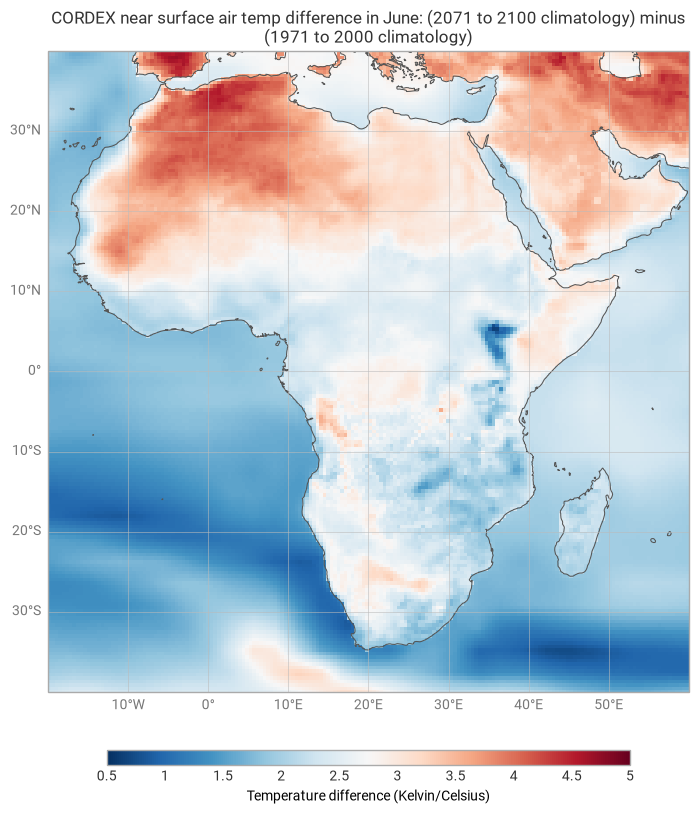

In [24]:
month = 6

style = ekp.Style(colors="RdBu_r", vmin=0.5, vmax=5, units="°C")

chart = ekp.Map(domain=[-20, 60, -40, 40])
chart.pcolormesh(tas_difference_climatology.sel(month=month), style=style)
chart.coastlines()
chart.gridlines()
chart.title(
    f"CORDEX near surface air temp difference in {calendar.month_name[month]}: "
    "(2071 to 2100 climatology) minus (1971 to 2000 climatology)"
)
chart.legend(label="Temperature difference (Kelvin/Celsius)")
chart.show()

As a last step, we repeat the visualization of climate change signal between the target (2071-2100) and reference (1971-2000) period. But this time, we create the average signal for the whole period, not only one month. For this, we have to compute the average over all months with the function `mean()`.

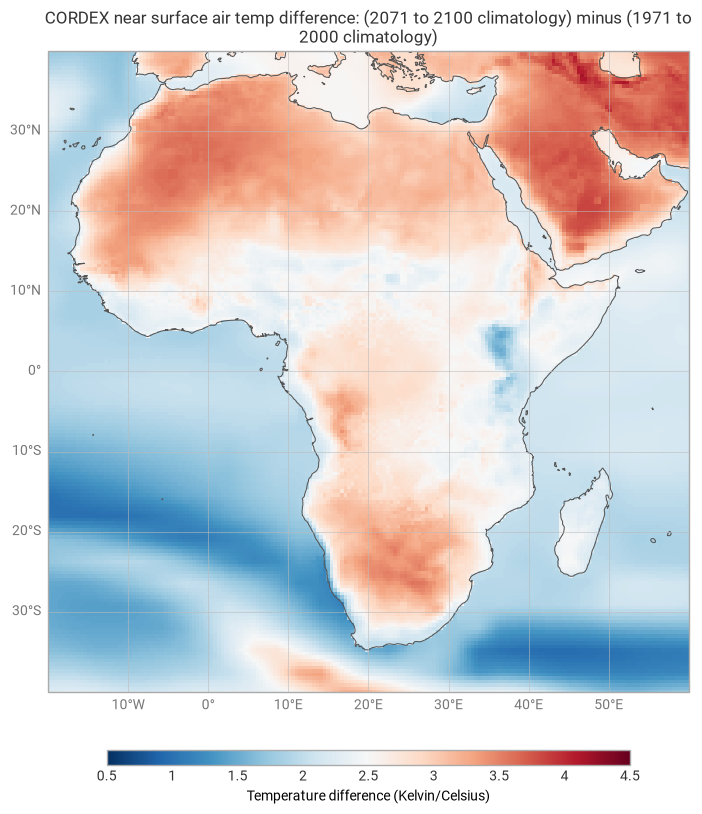

In [20]:
style = ekp.Style(colors="RdBu_r", vmin=0.5, vmax=4.5, units="celsius")

chart = ekp.Map(domain=[-20, 60, -40, 40])
chart.pcolormesh(tas_difference_climatology.mean("month"), style=style)
chart.coastlines()
chart.gridlines()
chart.title(
    "CORDEX near surface air temp difference: "
    "(2071 to 2100 climatology) minus (1971 to 2000 climatology)"
)
chart.legend(label="Temperature difference (Kelvin/Celsius)")
chart.show()

## Take home messages 📌

- CORDEX regional climate models provide climate projections at a higher spatial resolution than global models, for a specific regional domain.

- With the "delta method", the climate change signal is computed as the difference between a future and a historical climatology from the same model, assuming that the model biases are the same in both periods and are therefore removed by the subtraction.

- The projected change in near-surface air temperature varies between regions and between months, so looking at individual months as well as the annual average gives a more complete picture.

- This example uses a single model and scenario. To have a more accurate idea of projected climate change, an ensemble of multiple models should be used.